--- Initial Inspection ---
First 5 rows:
   Duration          Date  Pulse  Maxpulse  Calories
0        60  '2020/12/01'    110       130     409.1
1        60  '2020/12/02'    117       145     479.0
2        60  '2020/12/03'    103       135     340.0
3        45  '2020/12/04'    109       175     282.4
4        45  '2020/12/05'    117       148     406.0

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32 entries, 0 to 31
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Duration  32 non-null     int64  
 1   Date      31 non-null     object 
 2   Pulse     32 non-null     int64  
 3   Maxpulse  32 non-null     int64  
 4   Calories  30 non-null     float64
dtypes: float64(1), int64(3), object(1)
memory usage: 1.4+ KB
None

Missing values before cleaning:
Duration    0
Date        1
Pulse       0
Maxpulse    0
Calories    2
dtype: int64

Missing values after cleaning:
Duration    0
Date        0
Pulse   

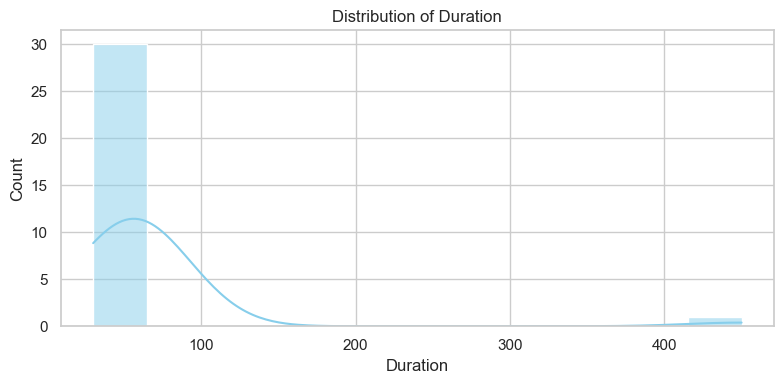

C:\Users\rohit\AppData\Local\Temp\ipykernel_22500\1054441815.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=categorical_cols[0], palette='Blues_d')


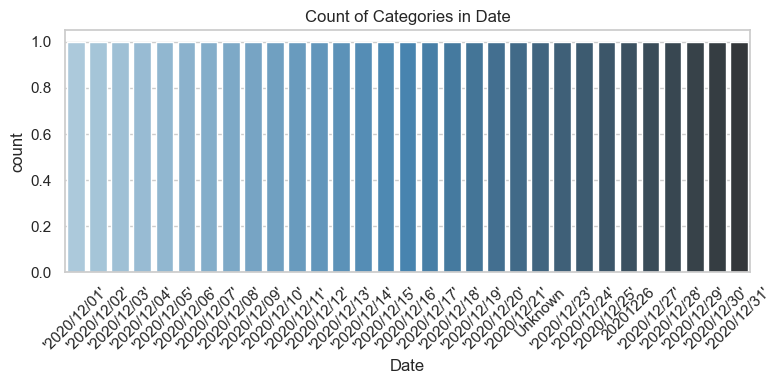


Success! Cleaned dataset saved to 'cleaned_data.csv'.


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('data.csv')
print("--- Initial Inspection ---")
print("First 5 rows:")
print(df.head())
print("\nDataset Info:")
print(df.info())
print("\nMissing values before cleaning:")
print(df.isnull().sum())
numeric_cols = df.select_dtypes(include=['number']).columns
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())
categorical_cols = df.select_dtypes(include=['object', 'category']).columns
for col in categorical_cols:
    df[col] = df[col].fillna('Unknown')

df = df.dropna(how='all')

print("\nMissing values after cleaning:")
print(df.isnull().sum())

df = df.drop_duplicates()

if len(numeric_cols) > 0:
    first_num_col = numeric_cols[0]
    df['is_above_average'] = df[first_num_col] > df[first_num_col].mean()


sns.set_theme(style="whitegrid")

if len(numeric_cols) > 0:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[numeric_cols[0]], kde=True, color='skyblue')
    plt.title(f'Distribution of {numeric_cols[0]}')
    plt.tight_layout()
    plt.show()

if len(categorical_cols) > 0:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df, x=categorical_cols[0], palette='Blues_d')
    plt.title(f'Count of Categories in {categorical_cols[0]}')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

df.to_csv('cleaned_data.csv', index=False)
print("\nSuccess! Cleaned dataset saved to 'cleaned_data.csv'.")

--- Initial Data ---
   Duration          Date  Pulse  Maxpulse  Calories
0        60  '2020/12/01'    110       130     409.1
1        60  '2020/12/02'    117       145     479.0
2        60  '2020/12/03'    103       135     340.0
3        45  '2020/12/04'    109       175     282.4
4        45  '2020/12/05'    117       148     406.0

Missing values before cleaning:
Duration    0
Date        1
Pulse       0
Maxpulse    0
Calories    2
dtype: int64


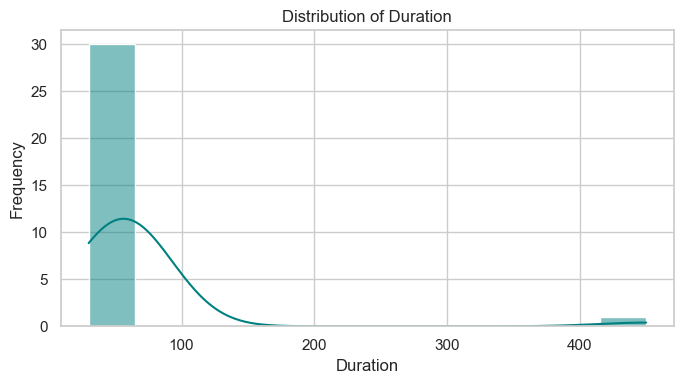


Done! Cleaned dataset saved as 'cleaned_data.csv'.


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data.csv')

print("--- Initial Data ---")
print(df.head())
print("\nMissing values before cleaning:")
print(df.isnull().sum())

num_cols = df.select_dtypes(include=['number']).columns
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

cat_cols = df.select_dtypes(include=['object', 'category']).columns
for col in cat_cols:
    df[col] = df[col].fillna('Unknown')

df = df.drop_duplicates()

if len(num_cols) > 0:
    target_col = num_cols[0]
    df['above_average'] = df[target_col] > df[target_col].mean()

sns.set_theme(style="whitegrid")

if len(num_cols) > 0:
    plt.figure(figsize=(7, 4))
    sns.histplot(df[num_cols[0]], kde=True, color='teal')
    plt.title(f'Distribution of {num_cols[0]}')
    plt.xlabel(num_cols[0])
    plt.ylabel('Frequency')
    plt.tight_layout()
    plt.show()

df.to_csv('cleaned_data.csv', index=False)
print("\nDone! Cleaned dataset saved as 'cleaned_data.csv'.")